# Grad-CAM Visualizations

Inspect model attention maps for representative samples.

In [25]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from torchvision import models
from torchvision.transforms import functional as TF

In [26]:
from pathlib import Path
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms

project_root = next(
    (path for path in [Path.cwd(), Path.cwd() / "MHIST-Research", *Path.cwd().parents]
     if (path / "data" / "metadata" / "test_split.csv").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate MHIST-Research/data/metadata/test_split.csv from the current directory.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class MHISTDataset(Dataset):
    def __init__(self, dataframe, images_path, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.images_path = images_path
        self.transform = transform
        self.label_map = {"HP": 0, "SSA": 1}

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        with Image.open(self.images_path / row["Image Name"]) as image:
            image = image.convert("RGB")
            if self.transform:
                image = self.transform(image)
        return image, self.label_map[row["Majority Vote Label"]]

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
test_df = pd.read_csv(project_root / "data" / "metadata" / "test_split.csv")
test_dataset = MHISTDataset(
    test_df,
    project_root / "data" / "raw" / "images" / "images",
    transform=transform,
)

checkpoint_paths = {
    "ResNet18": "resnet18.pth",
    "EfficientNet-B0": "efficientnet_b0.pth",
    "MobileNetV3-Small": "mobilenet_v3_small.pth",
    "ShuffleNetV2-x0.5": "shufflenet_v3_small.pth",
}
trained_models = {}
checkpoint_dir = project_root / "models" / "checkpoints"
for name, checkpoint_name in checkpoint_paths.items():
    if name == "ResNet18":
        model = models.resnet18(weights=None)
        model.fc = torch.nn.Linear(model.fc.in_features, 2)
    elif name == "EfficientNet-B0":
        model = models.efficientnet_b0(weights=None)
        model.classifier[1] = torch.nn.Linear(model.classifier[1].in_features, 2)
    elif name == "MobileNetV3-Small":
        model = models.mobilenet_v3_small(weights=None)
        model.classifier[3] = torch.nn.Linear(model.classifier[3].in_features, 2)
    else:
        model = models.shufflenet_v2_x0_5(weights=None)
        model.fc = torch.nn.Linear(model.fc.in_features, 2)

    checkpoint_path = checkpoint_dir / checkpoint_name
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"Checkpoint for {name} not found: {checkpoint_path}")
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    if "model_state_dict" in checkpoint:
        checkpoint = checkpoint["model_state_dict"]
    elif "state_dict" in checkpoint:
        checkpoint = checkpoint["state_dict"]
    checkpoint = {key.removeprefix("module."): value for key, value in checkpoint.items()}
    model.load_state_dict(checkpoint)
    trained_models[name] = model.to(device).eval()

print("CUDA available:", torch.cuda.is_available())
print("Test images:", len(test_dataset))
print("Models:", list(trained_models.keys()))

CUDA available: True
Test images: 977
Models: ['ResNet18', 'EfficientNet-B0', 'MobileNetV3-Small', 'ShuffleNetV2-x0.5']


In [27]:
def get_target_layer(model,model_name):
    if model_name=="ResNet18":
        return model.layer4[-1]
    elif model_name=="EfficientNet-B0":
            return model.features[-1]
    elif model_name=="MobileNetV3-Small":
            return model.features[-1]
    elif model_name=="ShuffleNetV2-x0.5":
            return model.conv5
    else:
          raise ValueError(f"Unsupported model: {model_name}")

In [28]:
def generate_gradcam(model,model_name,image,target_class=None):
    model.eval()
    target_layer=get_target_layer(model,model_name)
    activations={}
    def forward_hook(module,inputs,output):
        activations['features']=output
        output.retain_grad()
    hook=target_layer.register_forward_hook(forward_hook)
    model.zero_grad(set_to_none=True)
    image_batch = image.unsqueeze(0).to(device)
    output=model(image_batch)
    probabilities=torch.softmax(output,dim=1)
    predicted_class=int(output.argmax(dim=1).item())
    if target_class is None:
        target_class=predicted_class
    score=output[0,target_class]
    score.backward()
    feature_maps=activations["features"]
    gradients=feature_maps.grad
    weights=gradients.mean(dim=(2,3),keepdim=True)
    cam=(weights*feature_maps).sum(dim=1,keepdim=True)
    cam=torch.relu(cam)
    cam=torch.nn.functional.interpolate(cam,size=image.shape[1:],mode="bilinear",align_corners=False)
    cam=cam[0,0]
    cam=cam-cam.min()
    cam=cam/(cam.max()+1e-8)
    hook.remove()
    return (cam.detach().cpu().numpy(), predicted_class, probabilities[0].detach().cpu().numpy(), target_class)

In [29]:
image_index=0
image,true_label=test_dataset[image_index]
mean=torch.tensor([0.485,0.456,0.406]).view(3,1,1)
std=torch.tensor([0.229,0.224,0.225]).view(3,1,1)
display_image=(image*std+mean).clamp(0,1)
display_image=display_image.permute(1,2,0).numpy()
print("Image index:",image_index)
print("Ground-truth label:",("HP", "SSA")[int(true_label)])

Image index: 0
Ground-truth label: HP


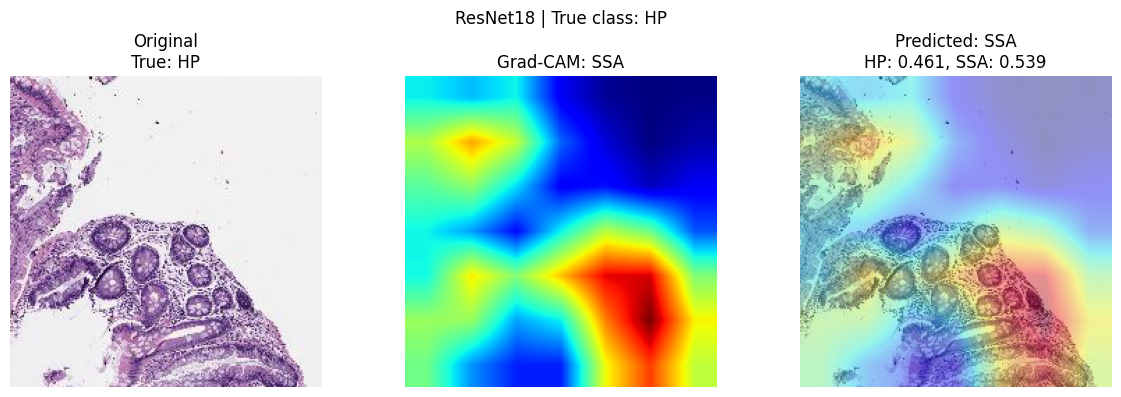

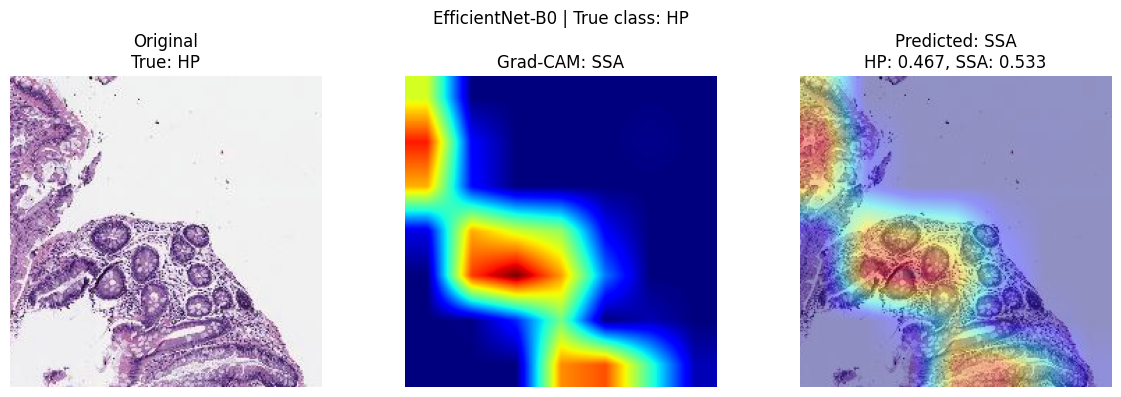

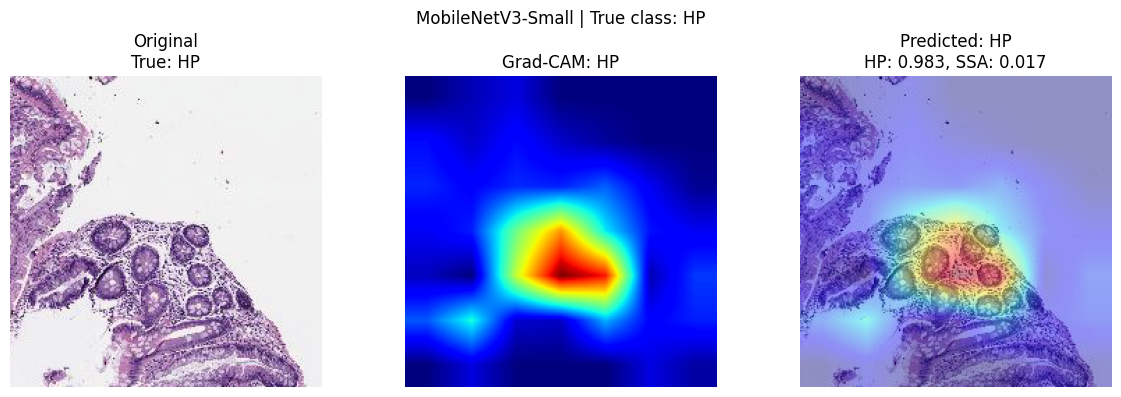

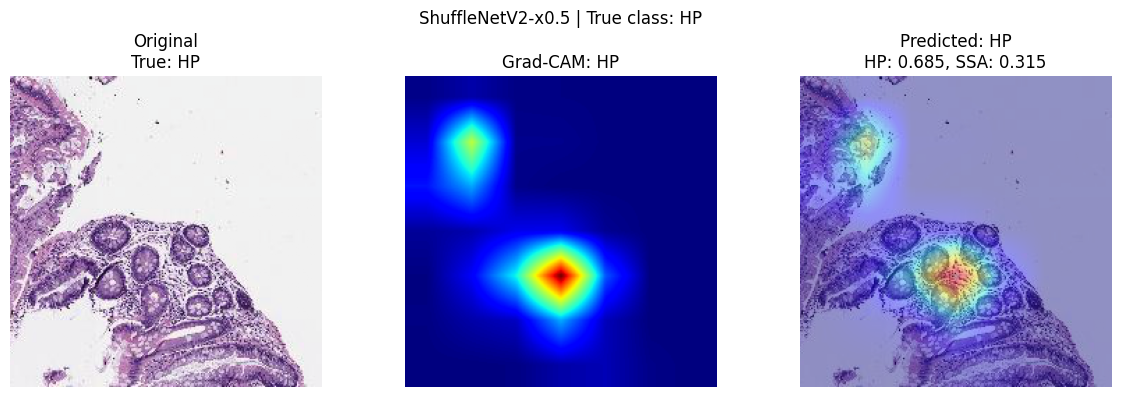

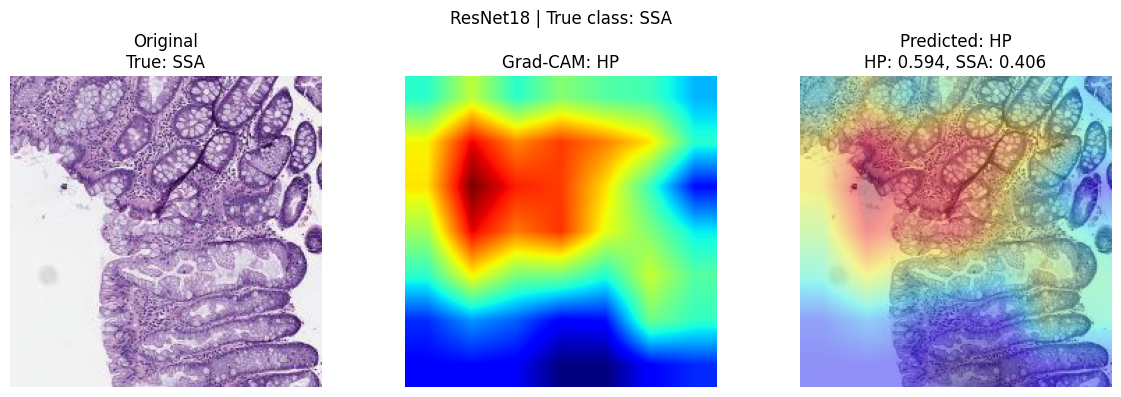

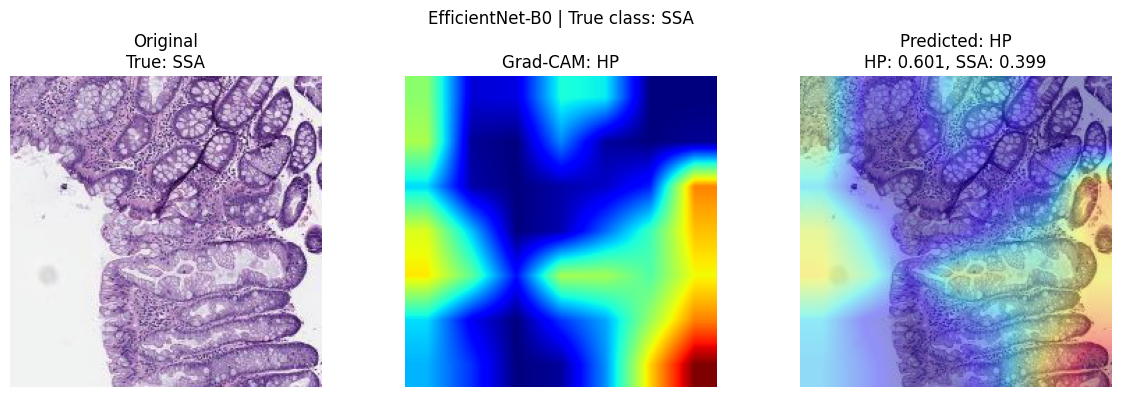

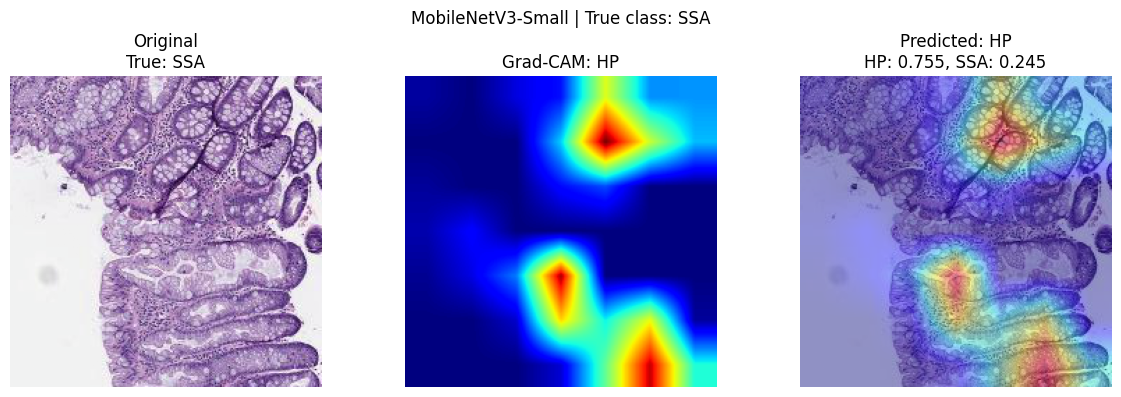

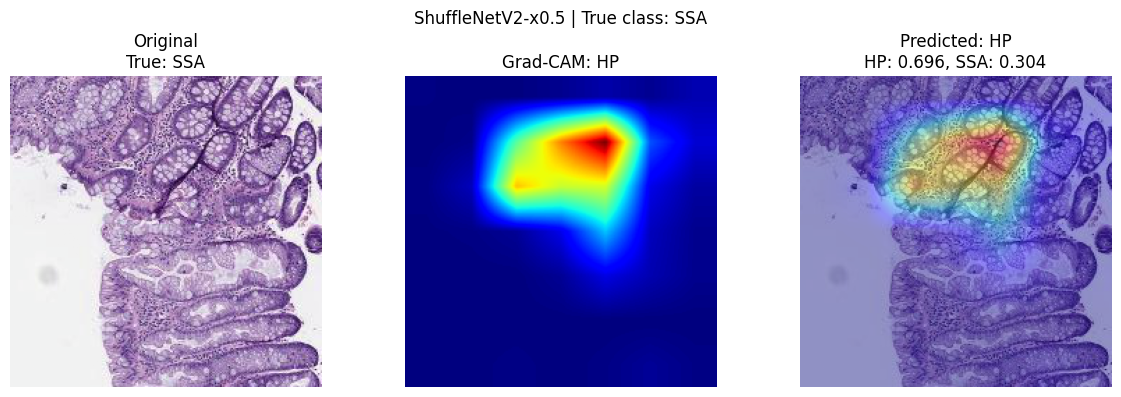

In [38]:
# Select one test image from each true class
hp_index = np.flatnonzero(test_df["Majority Vote Label"].to_numpy() == "HP")[0]
ssa_index = np.flatnonzero(test_df["Majority Vote Label"].to_numpy() == "SSA")[0]
sample_indices = {"HP": int(hp_index), "SSA": int(ssa_index)}
figures_dir = project_root / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
for true_name, image_index in sample_indices.items():
    image, true_label = test_dataset[image_index]

    # Undo ImageNet normalization for display
    
    display_image = (image * std + mean).clamp(0, 1)
    display_image = display_image.permute(1, 2, 0).numpy()

    for model_name, model in trained_models.items():

        # Explain the model's predicted class
        cam, pred, probs, target = generate_gradcam(model, model_name, image)
        fig, axes = plt.subplots(1, 3, figsize=(12, 4))
        axes[0].imshow(display_image)
        axes[0].set_title(f"Original\nTrue: {true_name}")
        axes[0].axis("off")
        axes[1].imshow(cam, cmap="jet", vmin=0, vmax=1)
        axes[1].set_title(f"Grad-CAM: {("HP", "SSA")[target]}")
        axes[1].axis("off")

        axes[2].imshow(display_image)
        axes[2].imshow(cam, cmap="jet", alpha=0.4,vmin=0, vmax=1)
        axes[2].set_title(
            f"Predicted: {("HP", "SSA")[pred]}\n"
            f"HP: {probs[0]:.3f}, SSA: {probs[1]:.3f}"
        )
        axes[2].axis("off")

        fig.suptitle(f"{model_name} | True class: {true_name}")
        plt.tight_layout()
        model_filename = model_name.lower().replace(" ", "_").replace("-", "_").replace(".", "_")
        fig.savefig(
            figures_dir / f"gradcam_{model_filename}_{true_name.lower()}.png",
            dpi=300, bbox_inches="tight",
        )
        plt.show()


In [35]:
hp_index = next(i for i in range(len(test_dataset)) if int(test_dataset[i][1]) == 0)
ssa_index = next(i for i in range(len(test_dataset)) if int(test_dataset[i][1]) == 1)
print("HP example index:", hp_index)
print("SSA example index:", ssa_index)

HP example index: 0
SSA example index: 2
